# FADEx — Case Study 1: Breast Cancer + UMAP (Fig. 7)


## Setup

In [1]:
# Colab: install the FADEx package (UMAP is preinstalled on Colab; added here for local runs)
%pip install -q fadex-exp umap-learn

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import umap

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.lines as mlines
import seaborn as sns

# Compatibility shim: the current FADEx release calls `matplotlib.cm.get_cmap`,
# which was removed in Matplotlib 3.11. Restore it before importing FADEx.
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

from fadex import FADEx

## Parameters

In [3]:
# ---- Embedding ----
USE_PAPER_EMBEDDING = True                          # False -> recompute UMAP
PAPER_EMBEDDING_CSV = "breast_cancer_umap_fig7.csv" # upload next to the notebook
UMAP_SEED = 42

# ---- FADEx ----
FADEX_NEIGHBORS = 100     # neighbourhood size used for Fig. 7
USE_PCA = False           # 30 features <= 50 -> no local PCA

# ---- Instances / regions shown in Fig. 7 (indices into load_breast_cancer()) ----
IDX_TOP = 5               # top of the Malignant cluster -> led by `mean concave points`
IDX_BOTTOM = 82           # bottom of the Malignant cluster -> led by `mean area`

# Transition zone between Benign and Malignant (circled in Fig. 7).
# Hand-picked list from the original notebook minus instance 466; with 466 included,
# the top-3 still match Fig. 7 but ranks 4-6 come out in a different order.
TRANSITION_IDS = [541, 496, 44, 526, 182, 566, 16, 277, 54, 171, 514, 126, 13,
                  448, 86, 91, 148, 288, 476, 184, 413, 291, 423, 558, 396, 99, 536]

HEATMAP_FEATURES = ["mean concave points", "mean area"]
VECTOR_FEATURE = "area error"

SAVE_FIGS = True          # FADEx saves its own plots as PDF in the working directory

## Data

In [4]:
bc = load_breast_cancer()
feature_names = list(bc.feature_names)
y = bc.target                                    # 0 = Malignant, 1 = Benign
class_names = np.where(y == 0, "Malignant", "Benign")

X = StandardScaler().fit_transform(bc.data)      # standardised features
print(X.shape, "| Malignant:", (y == 0).sum(), "| Benign:", (y == 1).sum())

(569, 30) | Malignant: 212 | Benign: 357


## Embedding

In [5]:
if USE_PAPER_EMBEDDING and Path(PAPER_EMBEDDING_CSV).exists():
    emb = pd.read_csv(PAPER_EMBEDDING_CSV).sort_values("index")
    X_umap = emb[["umap_1", "umap_2"]].to_numpy()
    print("Loaded the embedding used in the paper.")
else:
    if USE_PAPER_EMBEDDING:
        print(f"'{PAPER_EMBEDDING_CSV}' not found -> recomputing UMAP (layout will differ from Fig. 7).")
    X_umap = umap.UMAP(n_components=2, random_state=UMAP_SEED).fit_transform(X)

Loaded the embedding used in the paper.


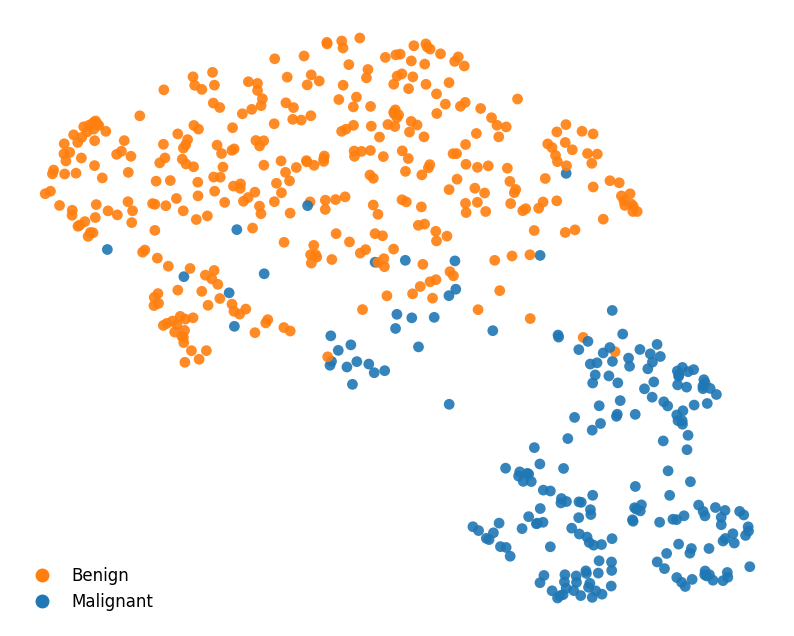

In [6]:
def plot_labels(ax, highlight=None):
    # UMAP layout coloured by class (tab10: Malignant = blue, Benign = orange)
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap="tab10", vmin=0, vmax=9,
               s=60, alpha=0.9, linewidths=0)
    handles = [mlines.Line2D([], [], marker="o", linestyle="None", markersize=9,
                             color=plt.get_cmap("tab10")(c), label=lbl)
               for c, lbl in [(1, "Benign"), (0, "Malignant")]]
    ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=12)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10, 8))
plot_labels(ax)
if SAVE_FIGS:
    fig.savefig("breast_cancer_labels.pdf", bbox_inches="tight")
plt.show()

The cell below marks the instances and the region analysed next: the two explained instances (stars) and the
transition-zone points (black outline).

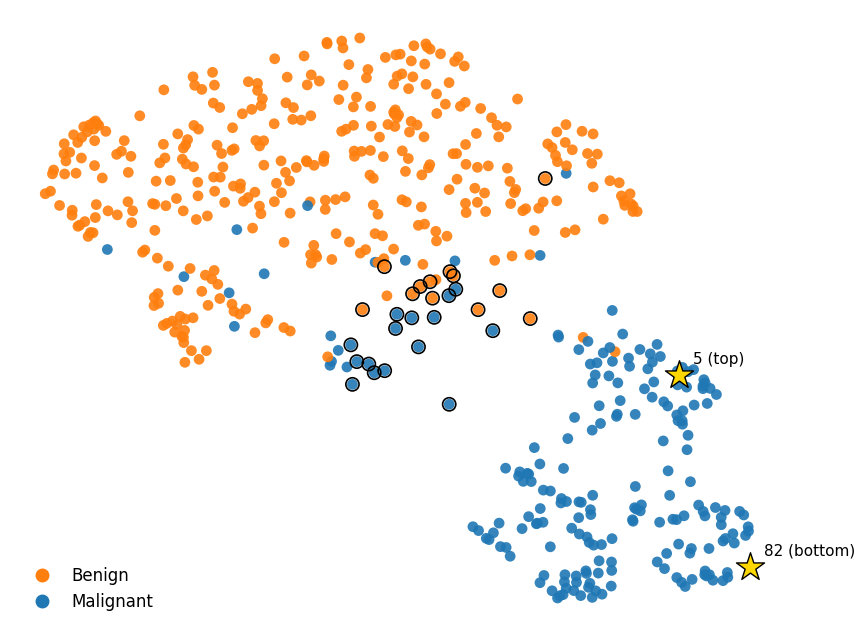

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
plot_labels(ax)
ax.scatter(*X_umap[TRANSITION_IDS].T, s=90, facecolors="none", edgecolors="black",
           linewidths=1.2, label="Transition zone")
for idx, txt in [(IDX_TOP, "top"), (IDX_BOTTOM, "bottom")]:
    ax.scatter(*X_umap[idx], s=450, marker="*", c="gold", edgecolors="black", zorder=5)
    ax.annotate(f"{idx} ({txt})", X_umap[idx], xytext=(10, 8), textcoords="offset points", fontsize=11)
plt.show()

## FADEx

In [8]:
fadex = FADEx(
    high_dim_data=X,
    low_dim_data=X_umap,
    n_neighbors=FADEX_NEIGHBORS,
    feature_names=feature_names,
    class_names=class_names,
    remove_const_feat=True,
    use_pca=USE_PCA,
)
fadex._fit_all()   # explanations for all 569 instances (cached for the plots below)

[FADEx] Processing Instances:   0%|          | 0/569 [00:00<?, ?instance/s]

## Instance explanations

Paper finding: `mean concave points` is the most important feature for the instance at the **top** of the Malignant
cluster, and `mean area` for the one at the **bottom**.

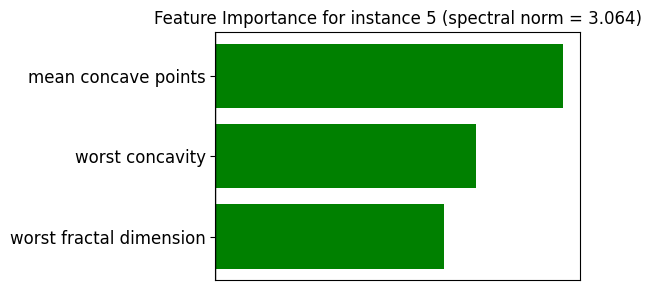

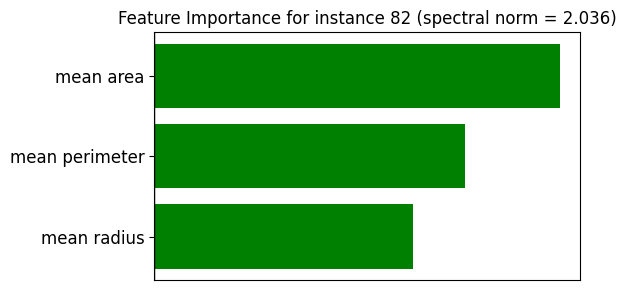

Instance 5:  ['mean concave points', 'worst concavity', 'worst fractal dimension']
Instance 82: ['mean area', 'mean perimeter', 'mean radius']


In [9]:
res_top = fadex.fit(IDX_TOP, n_top=3, width=6, height=3, save_fig=SAVE_FIGS)
res_bottom = fadex.fit(IDX_BOTTOM, n_top=3, width=6, height=3, save_fig=SAVE_FIGS)

print(f"Instance {IDX_TOP}:  {[str(f) for f in res_top['feature_names_top']]}")
print(f"Instance {IDX_BOTTOM}: {[str(f) for f in res_bottom['feature_names_top']]}")

## Importance heatmaps

Hexbin maps of the mean |φ| of a feature across the layout. Paper finding: `mean concave points` is important in
several regions, while `mean area` matters mainly in the lower part of the Malignant cluster.

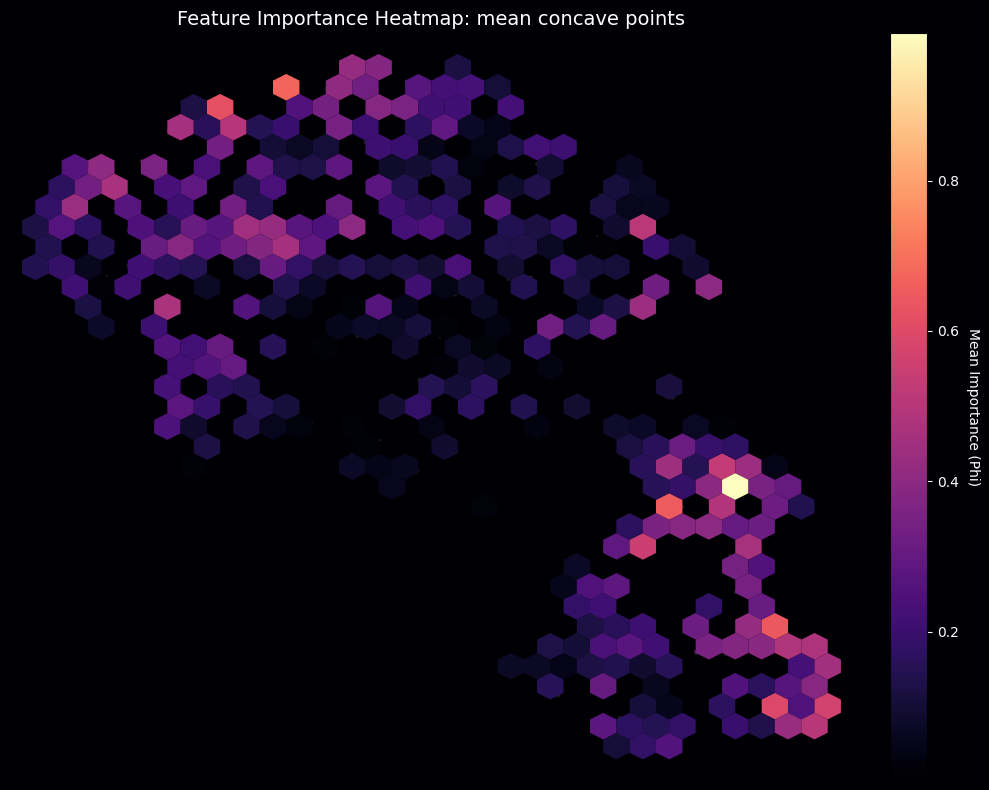

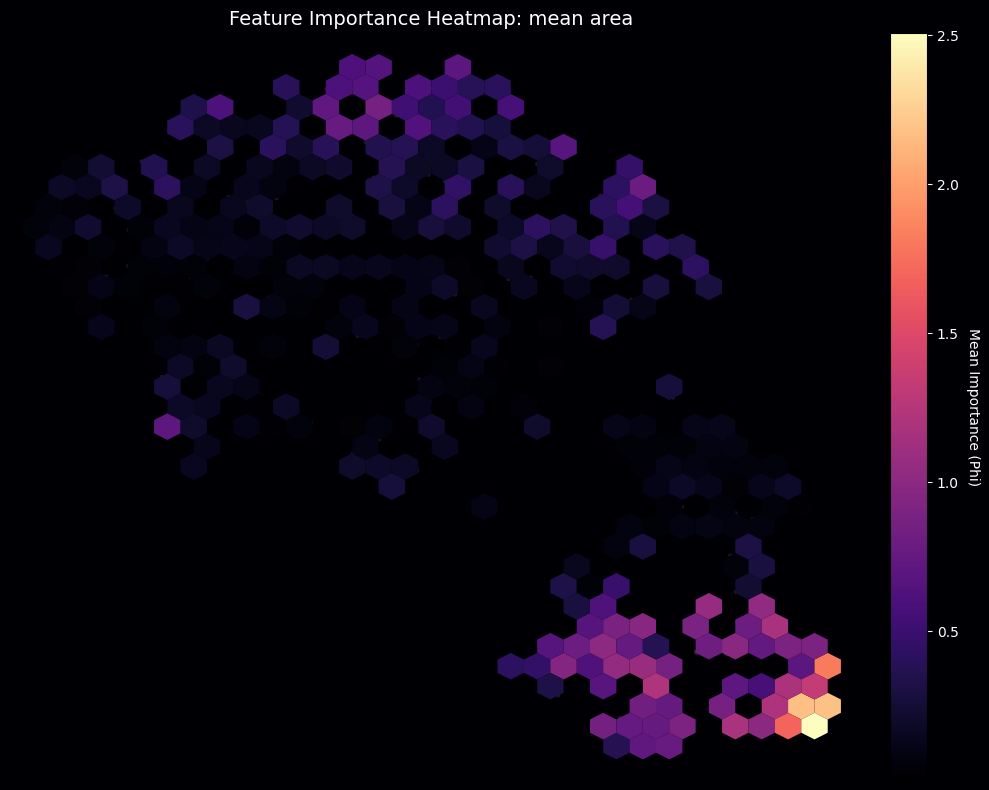

In [10]:
for feat in HEATMAP_FEATURES:
    fadex.plot_feature_heatmap(feature=feat, save=SAVE_FIGS)

## Transition zone

Average explanation over the instances lying between the two classes. Paper finding: `area error` is the most
influential feature, followed by `worst texture`, `worst smoothness`, `smoothness error`, `fractal dimension error`
and `worst compactness`.

  0%|          | 0/27 [00:00<?, ?it/s]

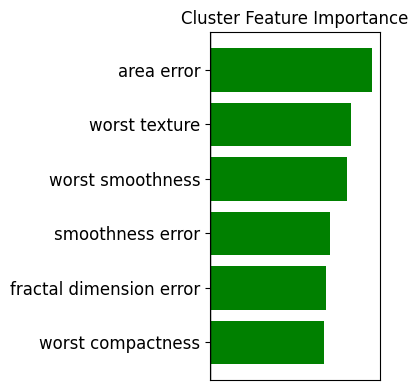

['area error', 'worst texture', 'worst smoothness', 'smoothness error', 'fractal dimension error', 'worst compactness']


In [11]:
res_transition = fadex.fit_cluster(cluster_ids=TRANSITION_IDS, n_top=6, show=True, save_fig=SAVE_FIGS)
print([str(f) for f in res_transition["feature_names_top"]])

## Feature Influence Vectors

The embedding is split into a 15 × 15 grid. In each cell, the mean Jacobian column of `area error` is drawn as an
arrow: the direction a point moves under a small increase of that feature. Paper finding: in the transition zone the
arrows point towards the Malignant cluster.

[FADEx] Computing grid cells:   0%|          | 0/112 [00:00<?, ?it/s]

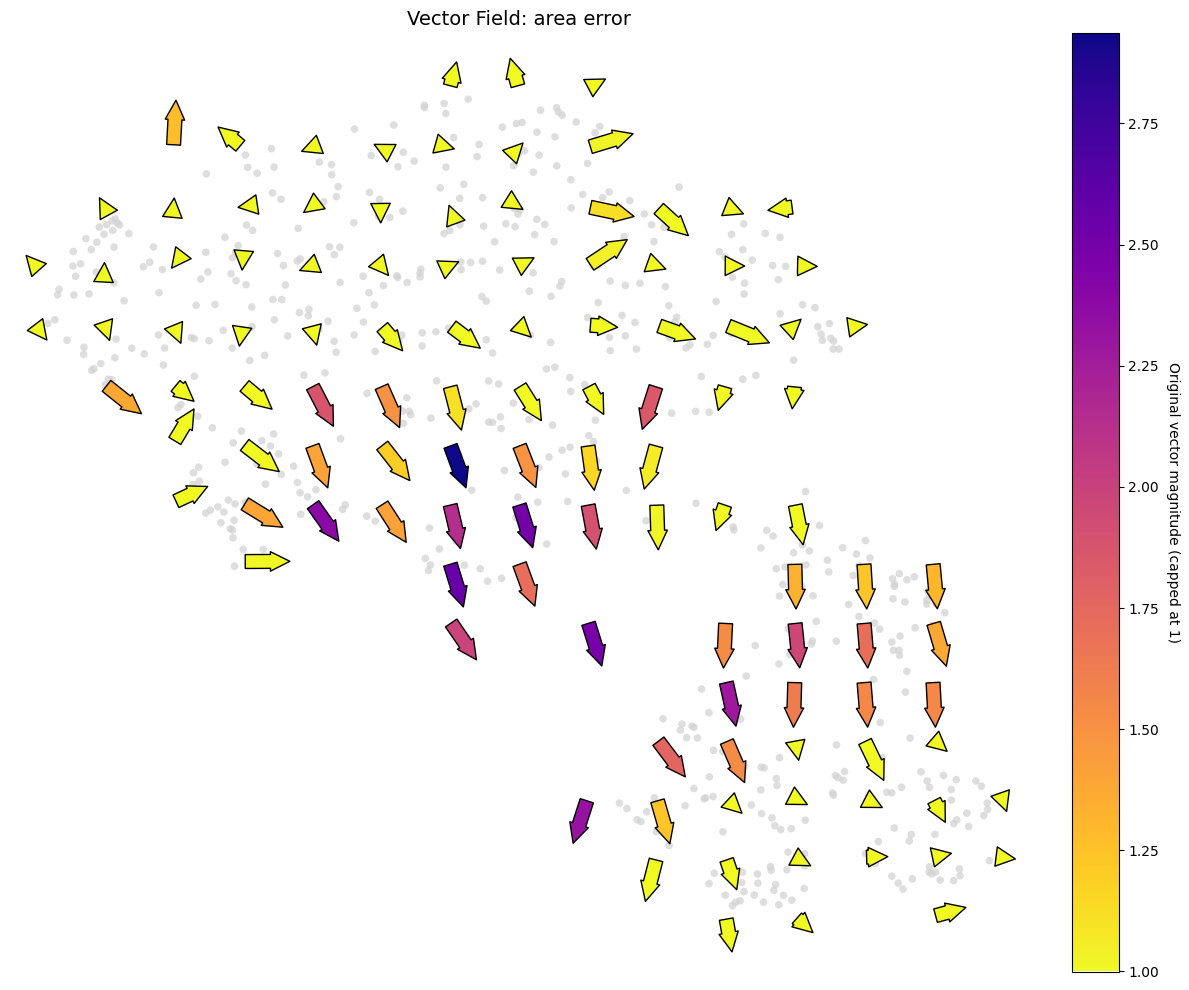

In [12]:
fadex.plot_grid_feature_vectors(feature=VECTOR_FEATURE, save_fig=SAVE_FIGS)

### Class-level explanations

In [14]:
for cls, name in [(0, "Malignant"), (1, "Benign")]:
    out = fadex.fit_cluster(cluster_ids=np.where(y == cls)[0], n_top=10)
    print(f"{name:9s} top-10: {[str(f) for f in out['feature_names_top']]}")

  0%|          | 0/212 [00:00<?, ?it/s]

Malignant top-10: ['mean area', 'mean perimeter', 'mean radius', 'worst radius', 'area error', 'worst area', 'mean concave points', 'worst perimeter', 'radius error', 'worst concavity']


  0%|          | 0/357 [00:00<?, ?it/s]

Benign    top-10: ['mean concavity', 'mean area', 'worst area', 'mean concave points', 'worst compactness', 'worst concave points', 'worst texture', 'mean texture', 'worst perimeter', 'worst concavity']
